In [1]:
# --- environment ---------------------------------------------------------------
# This notebook was written against the `scnomehic` conda environment.
#     conda env create -f env/scnomehic.yml && conda activate scnomehic
# See env/README.md for which notebook uses which environment.
_ENV_EXPECTED = "scnomehic"
import os as _os, sys as _sys
if _os.path.basename(_sys.prefix) != _ENV_EXPECTED:
    print(f"[env] expected the '{_ENV_EXPECTED}' environment, running in "
          f"'{_os.path.basename(_sys.prefix)}' ({_sys.prefix}). See env/README.md.",
          file=_sys.stderr)

# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import pyBigWig
from tqdm import tqdm
# Work from the benchmark tree; every path below is relative to it.
os.chdir(WORK + '/analysis/s3')

In [2]:
# Single cell line (GM12878) dataset: sc_nomehic_cellline/gm_sc_new
# (previously this used metadata_with_cell_type.txt, a MIXED GM12878 + IMR90 dataset)
GM_DIR = WORK + '/gm12878_cellline'

# Per-cell sample tables: <cell_name>\t<path to per-site .6plus2.bed>
#   GCH context = chromatin accessibility (GpC), HCG context = CpG methylation.
# This keeps the ORIGINAL single-cell methodology: compute per-site methy/cov WITHIN each
# cell, then pool those per-cell/per-site ratios across all cells (NOT pseudobulk).
# BisSNP-1.0.1 tables (.cyt.filtered.sort.*). The unsuffixed sample_table_{gch,hcg}
# point at the superseded BisSNP-0.90 (.calmd.cytosine.filtered.sort.*) output and are
# still consumed by collapse.sh; both are built by
# ../../data_processing/gm12878_cellline/02_qc/build_sample_tables.py
gch_table = pd.read_csv(f'{GM_DIR}/sample_table_gch_bissnp101.tsv.gz', sep='\t', header=None,
                        names=['cell', 'path'])
hcg_table = pd.read_csv(f'{GM_DIR}/sample_table_hcg_bissnp101.tsv.gz', sep='\t', header=None,
                        names=['cell', 'path'])
print(f'{len(gch_table)} GCH (accessibility) cells, {len(hcg_table)} HCG (methylation) cells')

188 GCH (accessibility) cells, 188 HCG (methylation) cells


In [3]:
# Single-cell methodology (matches the original figure):
# for each cell, the per-site methylation level is methy_reads / cov_reads. In the
# .6plus2.bed that ratio is already given as a percentage in column 7 (0-based index 6),
# so col7 / 100 == methy_reads / cov_reads within that cell. Pool across all cells.
#
# 188 cells x millions of sites is too large to hold in memory / feed to a KDE, so we
# subsample up to MAX_SITES_PER_CELL sites per cell (fixed seed for reproducibility).
# Set MAX_SITES_PER_CELL = None to pool every site.
MAX_SITES_PER_CELL = 50_000
_rng = np.random.default_rng(0)

def load_ratio(table, desc):
    vals = []
    for cell, path in tqdm(zip(table['cell'], table['path']), total=len(table), desc=desc):
        # Sample tables list the uncompressed name; files on disk are gzipped.
        p = path if os.path.exists(path) else path + '.gz'
        if not os.path.exists(p):
            print(f"⚠️ missing file for {cell}: {p}")
            continue

        # col 6 = per-site methylation level (%). skiprows=1 drops the 'track name=...' header.
        df = pd.read_csv(p, sep='\t', header=None, usecols=[6], names=['methlevel'],
                         skiprows=1, dtype='float32')

        v = df['methlevel'].to_numpy() / 100.0
        v = v[np.isfinite(v)]
        if MAX_SITES_PER_CELL is not None and v.size > MAX_SITES_PER_CELL:
            v = v[_rng.choice(v.size, MAX_SITES_PER_CELL, replace=False)]
        vals.append(v)

    return np.concatenate(vals) if vals else np.array([], dtype='float32')

acc = load_ratio(gch_table, 'GCH accessibility')
print(f'accessibility: {acc.size:,} pooled per-cell sites')

GCH accessibility:   0%|          | 0/188 [00:00<?, ?it/s]

GCH accessibility:   1%|          | 1/188 [00:07<23:24,  7.51s/it]

GCH accessibility:   1%|          | 2/188 [00:09<13:54,  4.49s/it]

GCH accessibility:   2%|▏         | 3/188 [00:13<12:54,  4.19s/it]

GCH accessibility:   2%|▏         | 4/188 [00:19<14:37,  4.77s/it]

GCH accessibility:   3%|▎         | 5/188 [00:23<13:23,  4.39s/it]

... (180 outputs left out)

GCH accessibility:  99%|█████████▉| 187/188 [12:01<00:04,  4.13s/it]

GCH accessibility: 100%|██████████| 188/188 [12:05<00:00,  3.98s/it]

GCH accessibility: 100%|██████████| 188/188 [12:05<00:00,  3.86s/it]

accessibility: 9,398,886 pooled per-cell sites


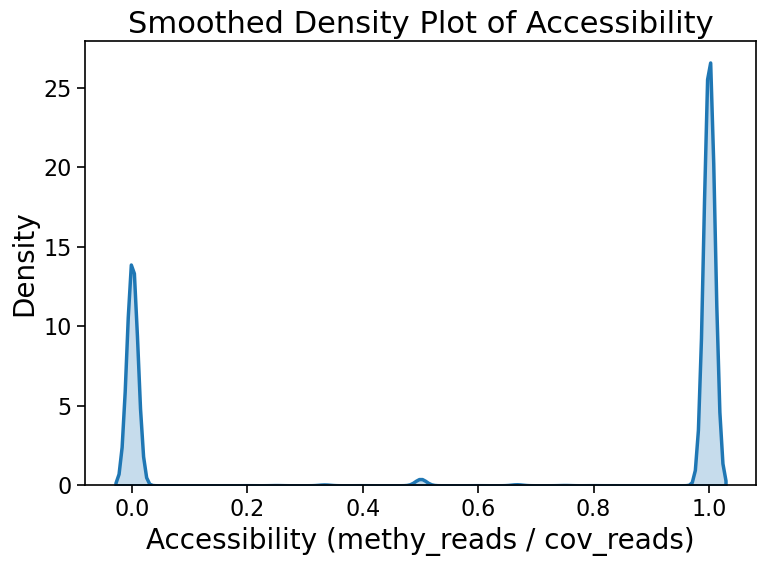

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Publication-size text (applies to both this and the methylation plot).
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 22,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'axes.linewidth': 1.2,
    'pdf.fonttype': 42,   # keep text editable (TrueType) in the PDF, not outlines
})

fig, ax = plt.subplots(figsize=(8, 6))

sns.kdeplot(acc, fill=True, bw_adjust=0.5, linewidth=2.5, ax=ax)

ax.set_xlabel("Accessibility (methy_reads / cov_reads)")
ax.set_ylabel("Density")
ax.set_title("Smoothed Density Plot of Accessibility")
ax.tick_params(width=1.2, length=6)

plt.tight_layout()
plt.savefig('acc_distribution.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [5]:
# Methylation: same per-cell per-site ratio, from the HCG (CpG) context.
methy = load_ratio(hcg_table, 'HCG methylation')
print(f'methylation: {methy.size:,} pooled per-cell sites')

HCG methylation:   0%|          | 0/188 [00:00<?, ?it/s]

HCG methylation:   1%|          | 1/188 [00:01<03:21,  1.08s/it]

HCG methylation:   1%|          | 2/188 [00:01<02:06,  1.47it/s]

HCG methylation:   2%|▏         | 3/188 [00:02<01:59,  1.54it/s]

HCG methylation:   2%|▏         | 4/188 [00:02<02:17,  1.34it/s]

HCG methylation:   3%|▎         | 5/188 [00:03<02:09,  1.42it/s]

... (180 outputs left out)

HCG methylation:  99%|█████████▉| 187/188 [02:14<00:00,  1.32it/s]

HCG methylation: 100%|██████████| 188/188 [02:15<00:00,  1.34it/s]

HCG methylation: 100%|██████████| 188/188 [02:15<00:00,  1.39it/s]

methylation: 9,359,311 pooled per-cell sites


In [6]:
# load_ratio already drops non-finite values; keep this as a defensive no-op filter.
# (Previously this read `acc[np.isfinite(methy)]`, which overwrote methy with accessibility.)
methy = methy[np.isfinite(methy)]

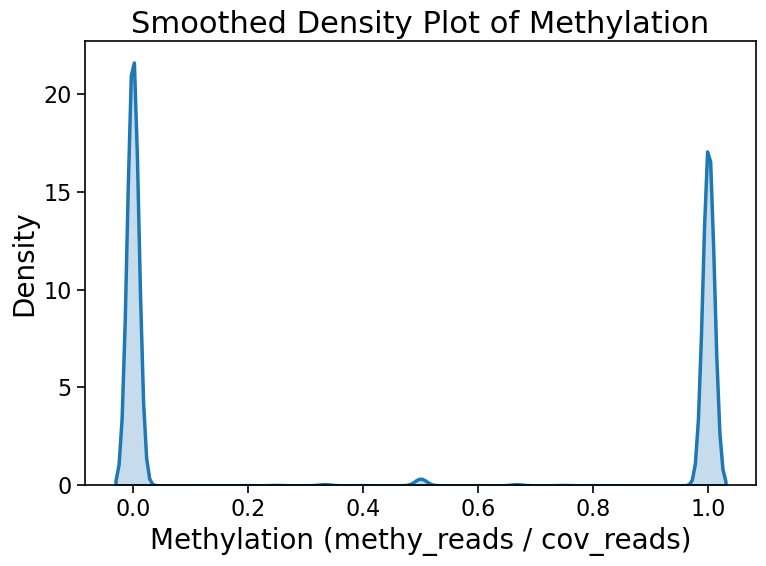

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Publication-size text (same settings as the accessibility plot).
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 22,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'axes.linewidth': 1.2,
    'pdf.fonttype': 42,
})

fig, ax = plt.subplots(figsize=(8, 6))

sns.kdeplot(methy, fill=True, bw_adjust=0.5, linewidth=2.5, ax=ax)

ax.set_xlabel("Methylation (methy_reads / cov_reads)")
ax.set_ylabel("Density")
ax.set_title("Smoothed Density Plot of Methylation")
ax.tick_params(width=1.2, length=6)

plt.tight_layout()
plt.savefig('methy_distribution.pdf', dpi=300, bbox_inches='tight')
plt.show()


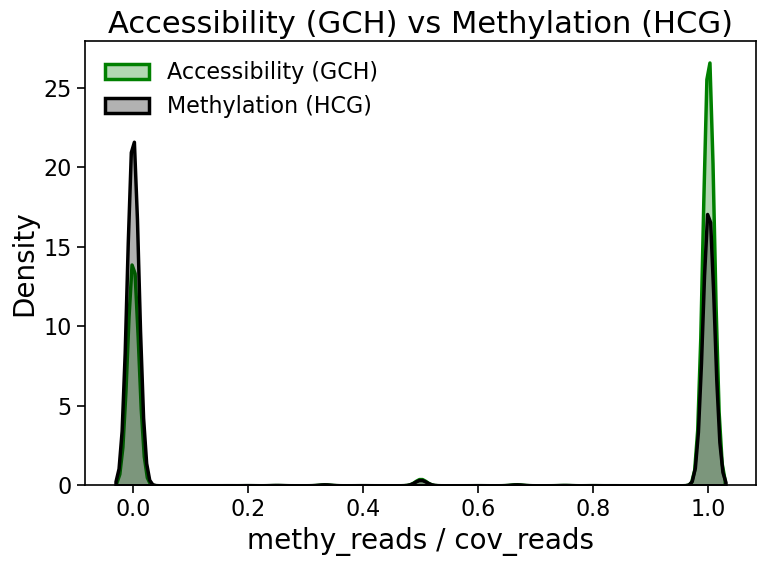

In [8]:
# Combined figure: accessibility (GCH) and methylation (HCG) on the SAME axes.
#   GCH (accessibility) = green
#   HCG (methylation)   = black
# Uses the same pooled single-cell arrays (`acc`, `methy`) and the same KDE settings
# (bw_adjust=0.5) as the two individual panels above, so the curves are identical --
# only the colors, legend and shared axes differ.
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 22,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'axes.linewidth': 1.2,
    'pdf.fonttype': 42,   # keep text editable (TrueType) in the PDF
})

GCH_COLOR = 'green'
HCG_COLOR = 'black'

fig, ax = plt.subplots(figsize=(8, 6))

sns.kdeplot(acc, fill=True, bw_adjust=0.5, linewidth=2.5, ax=ax,
            color=GCH_COLOR, alpha=0.30, label='Accessibility (GCH)')
sns.kdeplot(methy, fill=True, bw_adjust=0.5, linewidth=2.5, ax=ax,
            color=HCG_COLOR, alpha=0.30, label='Methylation (HCG)')

ax.set_xlabel("methy_reads / cov_reads")
ax.set_ylabel("Density")
ax.set_title("Accessibility (GCH) vs Methylation (HCG)")
ax.legend(frameon=False, fontsize=16)
ax.tick_params(width=1.2, length=6)

plt.tight_layout()
plt.savefig('acc_methy_distribution.pdf', dpi=300, bbox_inches='tight')
plt.show()
